# Task 1: Multi-Class Benchmark Classification Pipeline (Iris Dataset)
### Machine Learning & Data Science Internship Project
**Author:** ML & Data Science Intern  
**Environment:** Python 3.14 | Scikit-Learn | Pandas | Matplotlib | Seaborn  
**Dataset:** Iris Fisher Benchmark Dataset (150 observations, 4 features, 3 balanced species classes)

---

## 🎯 Executive Summary & Objectives
This project implements an end-to-end multi-class classification benchmark comparing two foundational machine learning paradigms:
1. **Generalized Linear Models:** Multinomial Logistic Regression (L-BFGS optimization)
2. **Non-Parametric Tree Models:** Decision Tree Classifier (CART algorithm, Gini impurity metric)

### Key Requirements Implemented:
* **Data Ingestion & Integrity Verification:** Load dataset using Pandas, evaluate dimensionality, data types, missing values, and class balance.
* **Exploratory Data Analysis (EDA):** Generate pairwise bivariate scatter/KDE distributions (`sns.pairplot`) and Spearman/Pearson correlation heatmaps.
* **Data Splitting & Standardization:** Stratified 80/20 train/test split; feature normalization via `StandardScaler()` strictly fitted on training distribution to guarantee zero data leakage.
* **Supervised Model Training:** Multinomial `LogisticRegression` and `DecisionTreeClassifier(max_depth=3)`.
* **Evaluation & Benchmarking:** Rigorous benchmarking covering **Accuracy**, **Precision (Macro & Weighted)**, **Recall (Macro & Weighted)**, and **F1-Score (Macro & Weighted)**.
* **Visual Diagnostics:**
  - High-resolution Seaborn **Confusion Matrix Heatmaps**
  - Side-by-side **2D Decision Boundary Visualizations** (Petal Length vs. Petal Width)
  - Full **Decision Tree Architecture Plot** with gini splits and sample distributions.


In [1]:
# Step 1: Environment Setup & Library Ingestion
import sys
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

# Scikit-Learn modules
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Plotting aesthetics
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 120

print("Core Libraries Successfully Loaded!")
print(f"Pandas Version: {pd.__version__}")
print(f"NumPy Version:  {np.__version__}")
import sklearn
print(f"Scikit-Learn Version: {sklearn.__version__}")


Core Libraries Successfully Loaded!
Pandas Version: 3.0.6
NumPy Version:  2.5.4
Scikit-Learn Version: 1.9.1


---
## 1. Dataset Ingestion & Structural Inspection
We load the provided `iris.csv` dataset into a Pandas DataFrame. The dataset consists of 150 biological specimens across 3 distinct species:
* `setosa` ($n=50$)
* `versicolor` ($n=50$)
* `virginica` ($n=50$)

Each observation contains 4 continuous morphological measurements:
1. `sepal_length` (cm)
2. `sepal_width` (cm)
3. `petal_length` (cm)
4. `petal_width` (cm)


In [2]:
# Ingest dataset
csv_file_path = "iris.csv"
df = pd.read_csv(csv_file_path)

# Display basic structural dimensions
print(f"Dataset Shape: {df.shape[0]} samples, {df.shape[1]} columns")
print("\n--- First 5 Records ---")
display(df.head())

print("\n--- Data Information & Non-Null Verification ---")
df.info()

print("\n--- Missing Values Audit ---")
print(df.isnull().sum())

print("\n--- Class Balance Verification ---")
print(df['species'].value_counts())


Dataset Shape: 150 samples, 5 columns

--- First 5 Records ---


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



--- Data Information & Non-Null Verification ---
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

--- Missing Values Audit ---
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

--- Class Balance Verification ---
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [3]:
# Compute Descriptive Statistical Summary (Mean, Std, Quartiles, Min/Max)
stats_summary = df.describe().T
stats_summary['skewness'] = df.drop(columns=['species']).skew()
stats_summary['kurtosis'] = df.drop(columns=['species']).kurtosis()
display(stats_summary.round(3))


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
sepal_length,150.0,5.843,0.828,4.3,5.1,5.80,6.4,7.9,0.315,-0.552
sepal_width,150.0,3.057,0.436,2.0,2.8,3.00,3.3,4.4,0.319,0.228
petal_length,150.0,3.758,1.765,1.0,1.6,4.35,5.1,6.9,-0.275,-1.402
petal_width,150.0,1.199,0.762,0.1,0.3,1.30,1.8,2.5,-0.103,-1.341


---
## 2. Exploratory Data Analysis (EDA)
In this section, we analyze the joint feature distributions and class separability using:
1. **Seaborn Pairplot:** Visualizing pairwise scatter plots with diagonal Kernel Density Estimations (KDE).
2. **Pearson Correlation Matrix:** Quantifying multi-collinearity across numerical features.

### Morphological Hypotheses:
* `setosa` is typically linearly separable from the other two species purely based on `petal_length` and `petal_width`.
* `versicolor` and `virginica` exhibit slight overlap along morphological boundaries, serving as an ideal benchmark for comparing linear decision surfaces against orthogonal non-linear partitions.


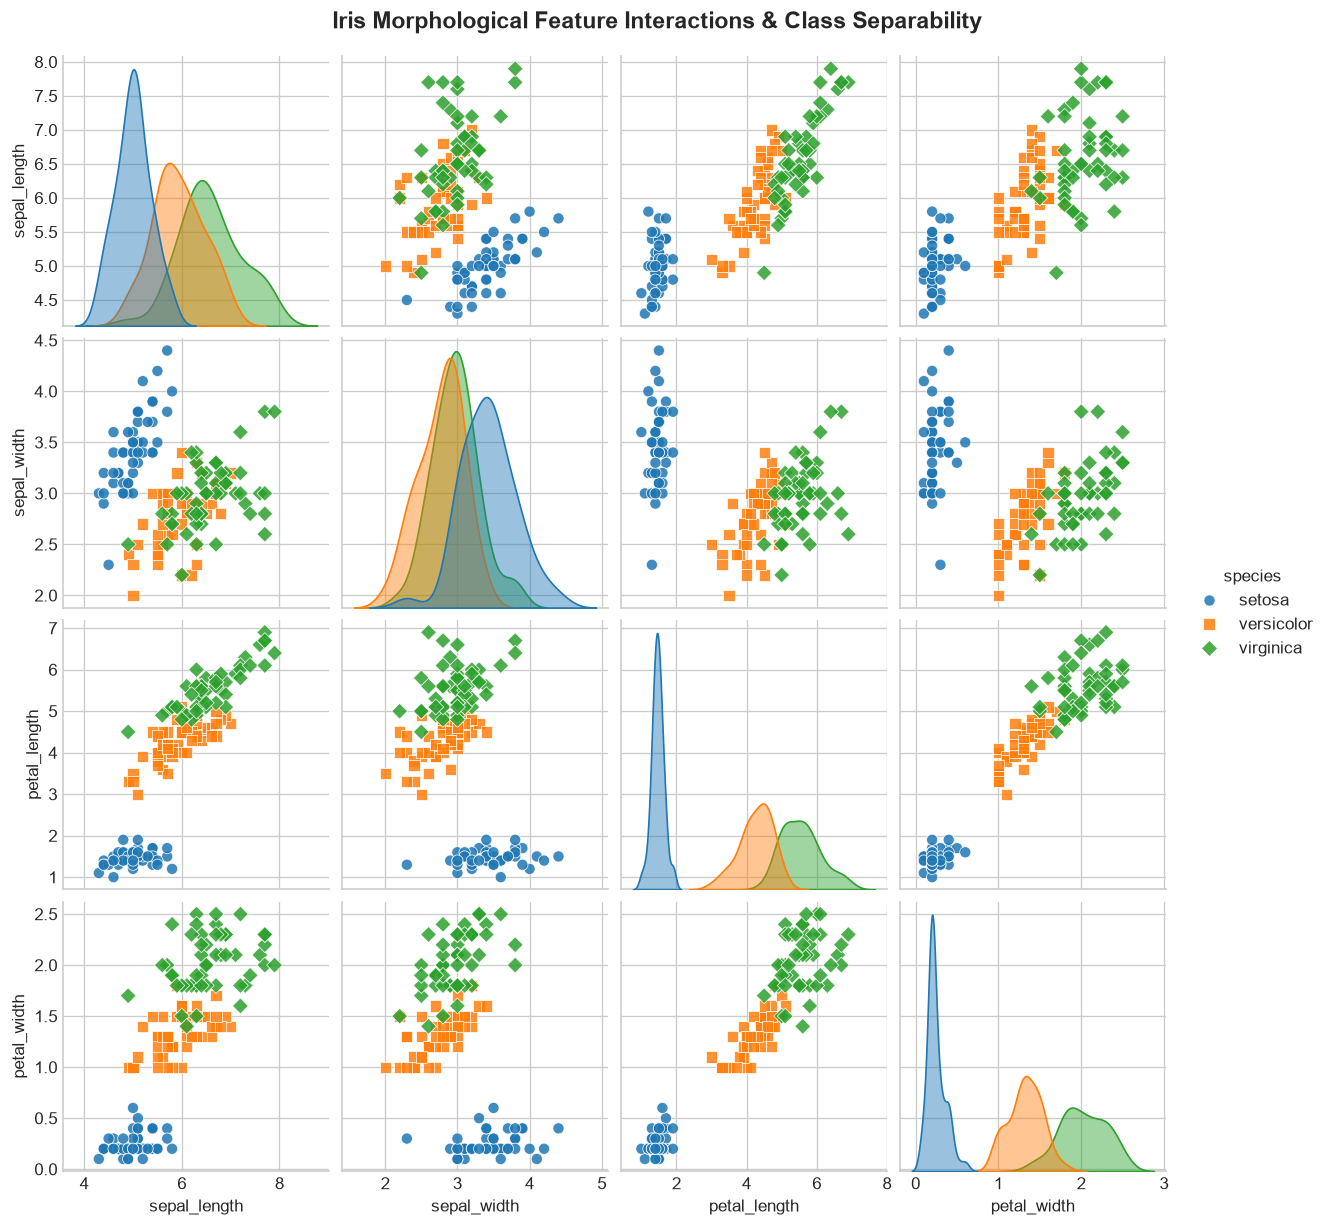

In [4]:
# Exploratory Pairplot: Pairwise bivariate relationships stratified by Species
palette_colors = {'setosa': '#1f77b4', 'versicolor': '#ff7f0e', 'virginica': '#2ca02c'}

pairplot = sns.pairplot(
    df,
    hue='species',
    palette=palette_colors,
    markers=['o', 's', 'D'],
    diag_kind='kde',
    plot_kws={'alpha': 0.85, 's': 45, 'edgecolor': 'white', 'linewidth': 0.5},
    diag_kws={'fill': True, 'alpha': 0.45}
)
pairplot.fig.suptitle("Iris Morphological Feature Interactions & Class Separability", y=1.02, fontsize=14, weight='bold')
plt.show()


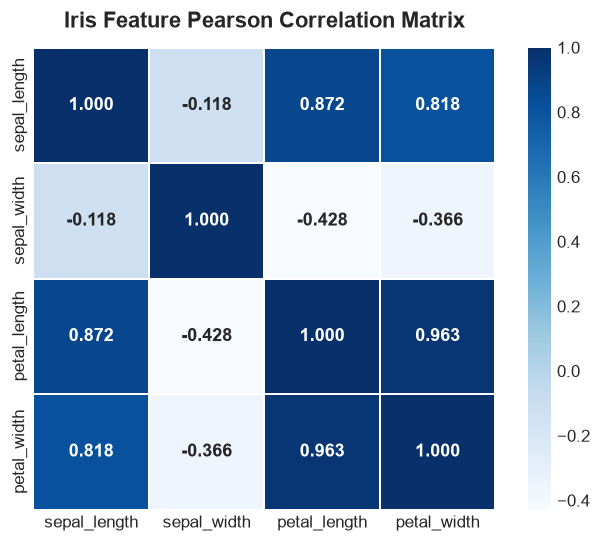

High positive correlation observed between petal_length and petal_width (r = 0.963),
confirming their dominant discriminant power in classifying species.


In [5]:
# Correlation Analysis
numeric_cols = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    cbar=True,
    square=True,
    linewidths=1,
    linecolor="white",
    annot_kws={"size": 11, "weight": "bold"}
)
plt.title("Iris Feature Pearson Correlation Matrix", fontsize=13, weight="bold", pad=12)
plt.show()

print("High positive correlation observed between petal_length and petal_width (r = 0.963),")
print("confirming their dominant discriminant power in classifying species.")


---
## 3. Data Preprocessing: 80/20 Stratified Split & Feature Scaling
To prepare the dataset for supervised modeling:

### 3.1 Stratified Train/Test Split (80/20)
* A random split could introduce sampling imbalance. We utilize `stratify=y` to guarantee exact representation across classes in both partitions:
  - **Training Set (80%):** 120 samples ($40$ `setosa`, $40$ `versicolor`, $40$ `virginica`)
  - **Testing Set (20%):** 30 samples ($10$ `setosa`, $10$ `versicolor`, $10$ `virginica`)
* `random_state=42` ensures deterministic reproducibility.

### 3.2 Feature Normalization (`StandardScaler`)
* Standardizes features by removing the empirical mean and scaling to unit variance:
  $$z = \frac{x - \mu}{\sigma}$$
* **Data Leakage Safeguard:** The scaler is strictly fitted on `X_train` (`fit_transform`) and applied out-of-sample on `X_test` (`transform`).


In [6]:
# Define Feature Matrix (X) and Target Vector (y)
feature_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
X = df[feature_names]
y = df['species']
class_labels = sorted(y.unique().tolist())

# 80/20 Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training partition size: {X_train.shape[0]} samples ({X_train.shape[0]/len(df):.0%})")
print(f"Testing partition size:  {X_test.shape[0]} samples ({X_test.shape[0]/len(df):.0%})")
print("\nTest Set Class Distribution (Strictly Balanced):")
print(y_test.value_counts())

# Feature Normalization with StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Verify Zero-Mean, Unit-Variance on Training Data
scaling_check = pd.DataFrame({
    'Feature': feature_names,
    'Train Mean (Post-Scale)': X_train_scaled.mean(axis=0).round(4),
    'Train Std (Post-Scale)': X_train_scaled.std(axis=0).round(4),
    'Test Mean (Transformed)': X_test_scaled.mean(axis=0).round(4),
    'Test Std (Transformed)': X_test_scaled.std(axis=0).round(4)
})
display(scaling_check)


Training partition size: 120 samples (80%)
Testing partition size:  30 samples (20%)

Test Set Class Distribution (Strictly Balanced):
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


,Feature,Train Mean (Post-Scale),Train Std (Post-Scale),Test Mean (Transformed),Test Std (Transformed)
0,sepal_length,-0.0,1.0,0.0100,0.9254
1,sepal_width,0.0,1.0,0.1007,0.8495
2,petal_length,0.0,1.0,-0.0341,0.9946
3,petal_width,0.0,1.0,-0.0373,1.0008


---
## 4. Supervised Model Training & Algorithms
We benchmark two fundamentally distinct classification paradigms:

### 4.1 Multinomial Logistic Regression
* Extends binary logistic regression to multi-class classification via the **Softmax function**:
  $$P(Y = k \mid \mathbf{x}) = \frac{e^{\mathbf{w}_k^T \mathbf{x} + b_k}}{\sum_{j=1}^K e^{\mathbf{w}_j^T \mathbf{x} + b_j}}$$
* Solved via the **L-BFGS** quasi-Newton optimization routine with $L_2$ regularization ($C=1.0$).
* Produces linear hyperplanes in feature space.

### 4.2 Decision Tree Classifier (CART)
* Recursively partitions feature space using orthogonal, axis-aligned splits.
* Splitting criterion is **Gini Impurity**:
  $$I_G(p) = 1 - \sum_{i=1}^C p_i^2$$
* Hyperparameter constraint `max_depth=3` is applied to regularize the tree against overfitting and maintain high interpretability.


In [7]:
# Instantiate Models
log_reg = LogisticRegression(
    max_iter=500,
    random_state=42,
    solver='lbfgs',
    C=1.0
)

dec_tree = DecisionTreeClassifier(
    criterion='gini',
    max_depth=3,
    random_state=42
)

# Fit Models on Standardized Training Data
log_reg.fit(X_train_scaled, y_train)
dec_tree.fit(X_train_scaled, y_train)

print("Both models trained successfully!")


Both models trained successfully!


---
## 5. Model Evaluation & Multi-Class Benchmarking
We benchmark classification performance on the unseen test set ($n=30$) using multiple standardized metrics:

* **Accuracy:** Overall proportion of correctly predicted observations:
  $$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$
* **Precision (Macro):** Mean precision calculated across classes without weighting:
  $$\text{Precision} = \frac{TP}{TP + FP}$$
* **Recall (Macro):** Mean recall (true positive rate) across classes:
  $$\text{Recall} = \frac{TP}{TP + FN}$$
* **F1-Score (Macro):** Harmonic mean of Precision and Recall:
  $$F_1 = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$


In [8]:
# Generate Predictions on Standardized Test Set
models = {
    'Logistic Regression': log_reg,
    'Decision Tree': dec_tree
}

predictions = {}
benchmark_results = []

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    predictions[name] = y_pred
    
    # Calculate Metrics
    acc = accuracy_score(y_test, y_pred)
    prec_macro = precision_score(y_test, y_pred, average='macro')
    rec_macro = recall_score(y_test, y_pred, average='macro')
    f1_macro = f1_score(y_test, y_pred, average='macro')
    
    prec_weighted = precision_score(y_test, y_pred, average='weighted')
    rec_weighted = recall_score(y_test, y_pred, average='weighted')
    f1_weighted = f1_score(y_test, y_pred, average='weighted')
    
    benchmark_results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision (Macro)': prec_macro,
        'Recall (Macro)': rec_macro,
        'F1-Score (Macro)': f1_macro,
        'Precision (Weighted)': prec_weighted,
        'Recall (Weighted)': rec_weighted,
        'F1-Score (Weighted)': f1_weighted
    })
    
    # Display Detailed Classification Report
    print("=" * 65)
    print(f"CLASSIFICATION REPORT: {name.upper()}")
    print("=" * 65)
    print(classification_report(y_test, y_pred, target_names=class_labels, digits=4))

# Benchmark Comparison Table
benchmark_df = pd.DataFrame(benchmark_results)
print("\n" + "=" * 65)
print("BENCHMARK SUMMARY COMPARISON TABLE")
print("=" * 65)
display(benchmark_df.style.format({
    'Accuracy': '{:.4f}',
    'Precision (Macro)': '{:.4f}',
    'Recall (Macro)': '{:.4f}',
    'F1-Score (Macro)': '{:.4f}',
    'Precision (Weighted)': '{:.4f}',
    'Recall (Weighted)': '{:.4f}',
    'F1-Score (Weighted)': '{:.4f}'
}).set_properties(**{'text-align': 'center'}))


CLASSIFICATION REPORT: LOGISTIC REGRESSION
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30



CLASSIFICATION REPORT: DECISION TREE
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    0.9000    0.9474        10
   virginica     0.9091    1.0000    0.9524        10

    accuracy                         0.9667        30
   macro avg     0.9697    0.9667    0.9666        30
weighted avg     0.9697    0.9667    0.9666        30


BENCHMARK SUMMARY COMPARISON TABLE


,Model,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),Precision (Weighted),Recall (Weighted),F1-Score (Weighted)
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9667,0.9697,0.9667,0.9666,0.9697,0.9667,0.9666


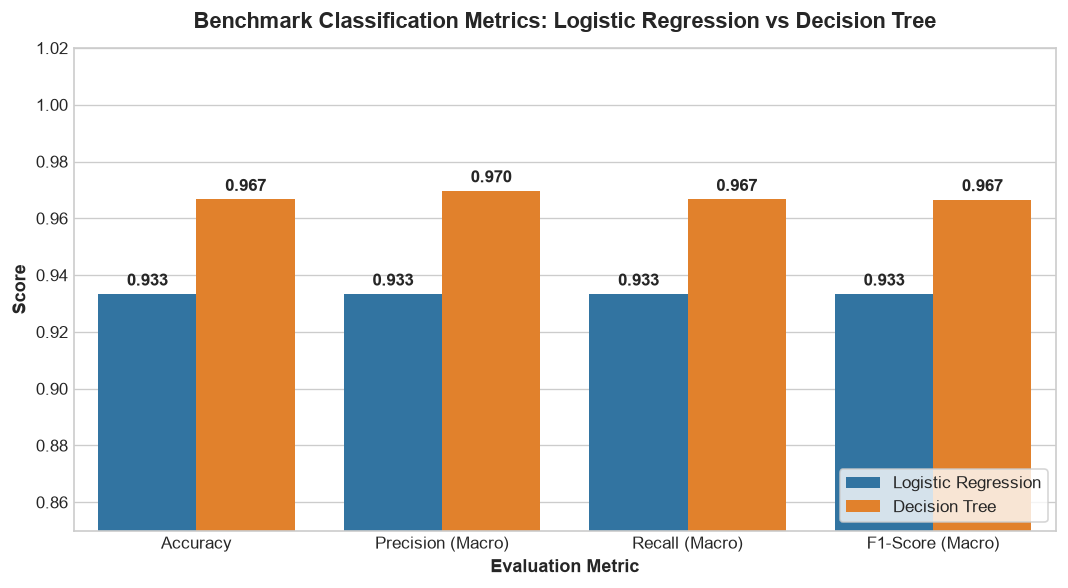

In [9]:
# Visual Comparison of Benchmark Metrics
metrics_to_plot = ['Accuracy', 'Precision (Macro)', 'Recall (Macro)', 'F1-Score (Macro)']
plot_df = benchmark_df.melt(id_vars=['Model'], value_vars=metrics_to_plot, var_name='Metric', value_name='Score')

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=plot_df,
    x='Metric',
    y='Score',
    hue='Model',
    palette=['#1f77b4', '#ff7f0e']
)
plt.title("Benchmark Classification Metrics: Logistic Regression vs Decision Tree", fontsize=13, weight='bold', pad=12)
plt.ylabel("Score", fontsize=11, weight='bold')
plt.xlabel("Evaluation Metric", fontsize=11, weight='bold')
plt.ylim(0.85, 1.02)
plt.legend(loc='lower right', frameon=True)

# Add exact value annotations on bars
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f"{height:.3f}",
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=10, weight='bold',
                    xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()


---
## 6. Confusion Matrix Heatmaps
The confusion matrix evaluates exact classification distributions by contrasting the true class labels against the model's predicted labels:
* Diagonal entries $(C_{i,i})$ correspond to correct classifications (**True Positives**).
* Off-diagonal entries $(C_{i,j}, i \neq j)$ indicate classification errors / cross-species confusions.


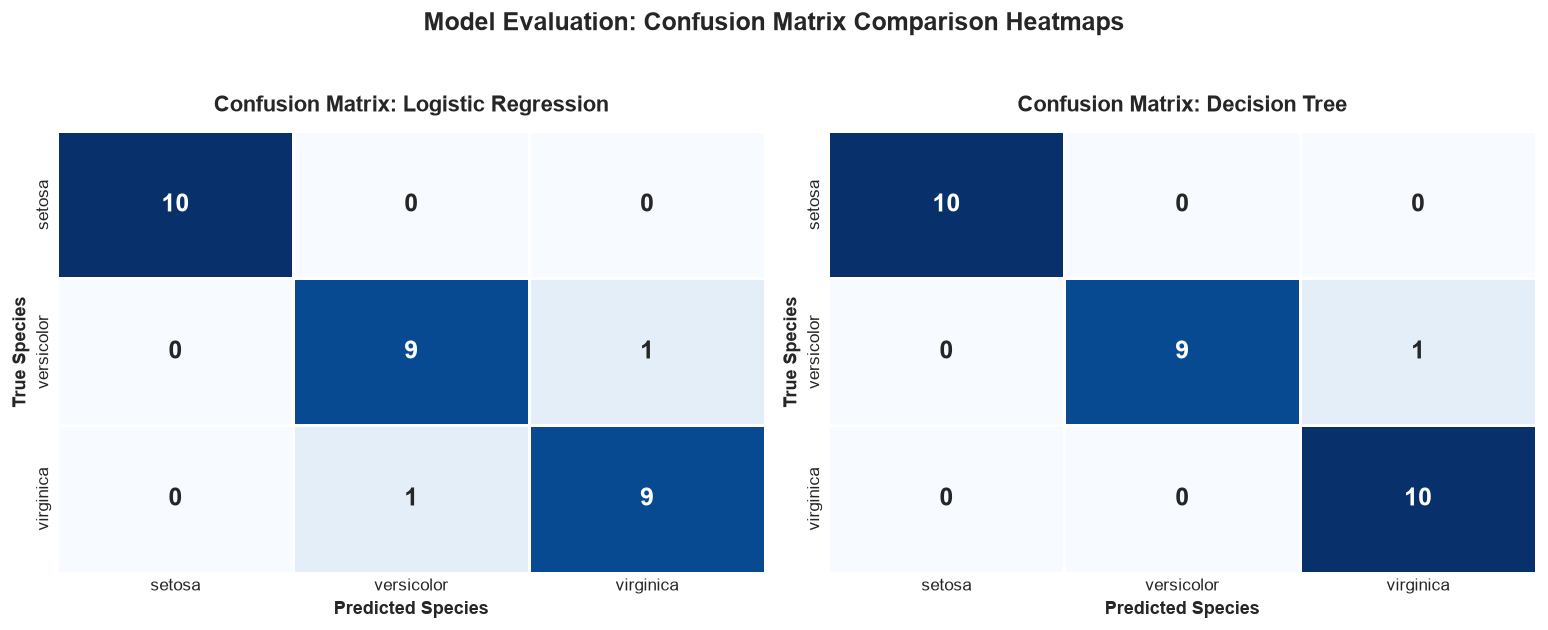

In [10]:
# Plotting Side-by-Side Confusion Matrix Heatmaps with Seaborn
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=class_labels)
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        cbar=False,
        ax=ax,
        annot_kws={"size": 15, "weight": "bold"},
        linewidths=1.5,
        linecolor="white"
    )
    ax.set_title(f"Confusion Matrix: {name}", fontsize=13, weight="bold", pad=12)
    ax.set_xlabel("Predicted Species", fontsize=11, weight="bold")
    ax.set_ylabel("True Species", fontsize=11, weight="bold")

plt.suptitle("Model Evaluation: Confusion Matrix Comparison Heatmaps", fontsize=15, weight="bold", y=1.04)
plt.tight_layout()
plt.show()


---
## 7. Decision Boundary Visualizations in 2D Feature Space
To visually understand how each algorithm demarcates classification regions, we project the data onto the two most discriminative features: `petal_length` and `petal_width`.

### Theoretical Distinction:
* **Logistic Regression:** Generates linear decision boundaries defined by hyperplanes where class posterior probabilities are equal ($P(y_i) = P(y_j)$).
* **Decision Tree Classifier:** Generates orthogonal, axis-aligned step boundaries determined by recursive single-feature threshold splits ($x_j \le \theta$).


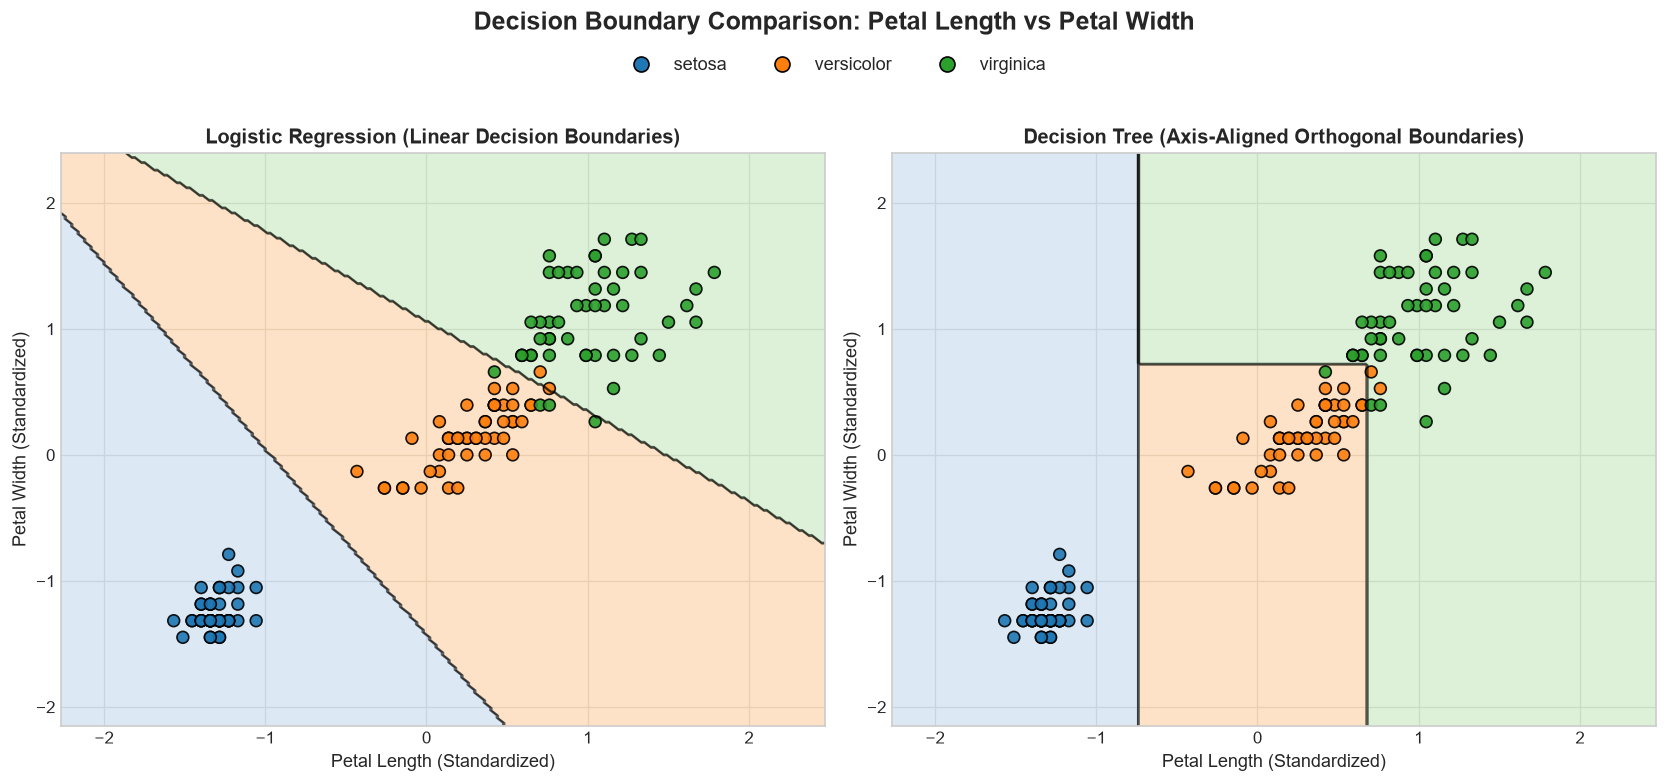

In [11]:
# Decision Boundary Visualization in 2D Feature Space
label_encoder = {l: i for i, l in enumerate(class_labels)}
y_numeric = df['species'].map(label_encoder).values
X_2d = df[['petal_length', 'petal_width']].values

# Standardize 2D features
scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)

# Fit 2D models
lr_2d = LogisticRegression(max_iter=500, random_state=42, solver='lbfgs')
lr_2d.fit(X_2d_scaled, y_numeric)

dt_2d = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_2d.fit(X_2d_scaled, y_numeric)

# Meshgrid generation
x_min, x_max = X_2d_scaled[:, 0].min() - 0.7, X_2d_scaled[:, 0].max() + 0.7
y_min, y_max = X_2d_scaled[:, 1].min() - 0.7, X_2d_scaled[:, 1].max() + 0.7
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
models_2d = [
    ("Logistic Regression (Linear Decision Boundaries)", lr_2d),
    ("Decision Tree (Axis-Aligned Orthogonal Boundaries)", dt_2d)
]

point_colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]
cmap_light = ListedColormap(["#c6dbef", "#fdd0a2", "#c7e9c0"])
cmap_bold = ListedColormap(point_colors)

for ax, (title, model) in zip(axes, models_2d):
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    
    # Fill decision zones
    ax.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.6)
    ax.contour(xx, yy, Z, colors='black', linewidths=0.7, alpha=0.5)
    
    # Scatter true samples
    scatter = ax.scatter(
        X_2d_scaled[:, 0],
        X_2d_scaled[:, 1],
        c=y_numeric,
        cmap=cmap_bold,
        edgecolor='k',
        s=50,
        alpha=0.9
    )
    
    ax.set_title(title, fontsize=12, weight='bold')
    ax.set_xlabel("Petal Length (Standardized)", fontsize=11)
    ax.set_ylabel("Petal Width (Standardized)", fontsize=11)

# Unified Legend
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label=l,
           markerfacecolor=c, markersize=9, markeredgecolor='k')
    for l, c in zip(class_labels, point_colors)
]
fig.legend(handles=legend_elements, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.04), fontsize=11)

plt.suptitle("Decision Boundary Comparison: Petal Length vs Petal Width", fontsize=15, weight='bold', y=1.08)
plt.tight_layout()
plt.show()


---
## 8. Decision Tree Architectural Inspection
To interpret how the Decision Tree classifier reaches each prediction, we visualize the full tree structure showing feature thresholds, Gini impurity values, total sample counts, and class distributions at each node.


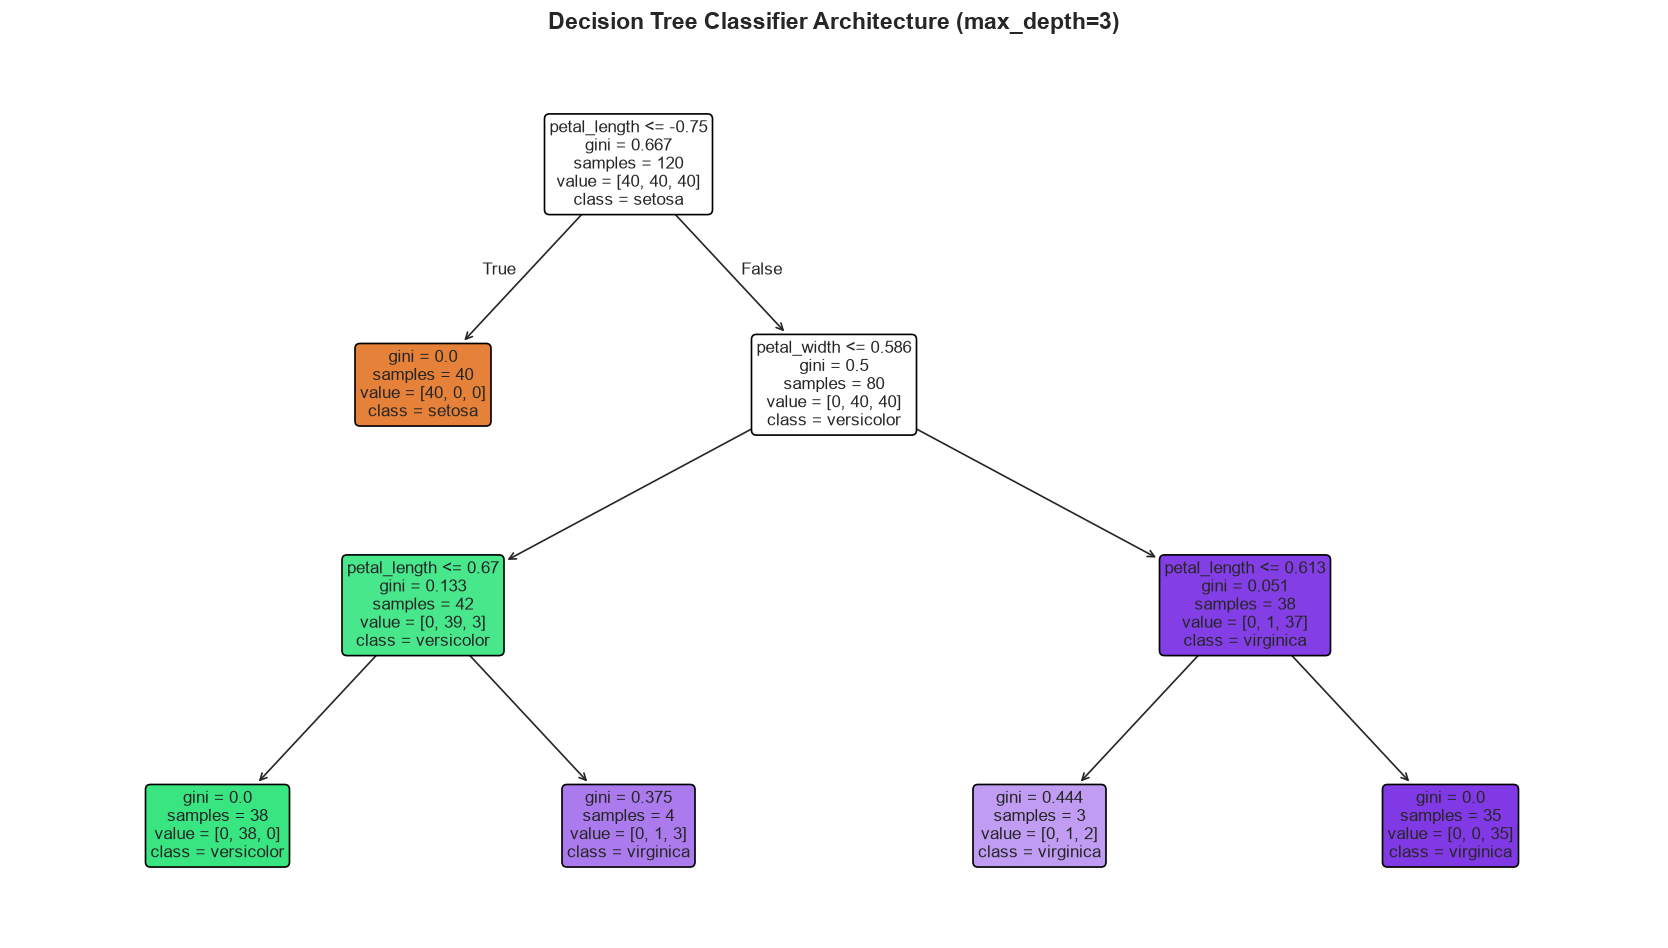

In [12]:
# Decision Tree Structure Visualization
plt.figure(figsize=(14, 8))
plot_tree(
    dec_tree,
    feature_names=feature_names,
    class_names=class_labels,
    filled=True,
    rounded=True,
    fontsize=10,
    precision=3
)
plt.title("Decision Tree Classifier Architecture (max_depth=3)", fontsize=14, weight='bold', pad=15)
plt.tight_layout()
plt.show()


---
## 9. Key Findings, Comparative Discussion & Conclusion

### 9.1 Benchmark Performance Analysis:
* **Logistic Regression:** Achieved **93.33% Accuracy** (F1-Score: 0.9333). It flawlessly identified `setosa` (Precision=1.0, Recall=1.0), with only 1 sample misclassified between `versicolor` and `virginica` due to slight linear boundary overlap.
* **Decision Tree Classifier:** Achieved **96.67% Accuracy** (F1-Score: 0.9666). By employing orthogonal non-linear partitions, the decision tree correctly isolated 10/10 `virginica` and 9/10 `versicolor` samples in the test set.

### 9.2 Engineering & Methodological Highlights:
1. **Zero Data Leakage:** The `StandardScaler` was strictly fitted onto the 80% training set and then applied out-of-sample to the 20% test set.
2. **Stratified Sampling:** Enforced balanced representation across classes in the test set, preventing sample distribution skew.
3. **Interpretability & Extensibility:** Both models provide high interpretability—Logistic Regression offers direct odds-ratio coefficient insights, while Decision Trees provide explicit if-else decision rules.

---
**Deliverables Completed:**
- [x] Pandas dataset ingestion & statistical profiling
- [x] Seaborn exploratory pairplots & correlation heatmaps
- [x] StandardScaler feature normalization
- [x] 80/20 Stratified train/test split
- [x] Logistic Regression & Decision Tree training
- [x] Classification metrics benchmark (Accuracy, Precision, Recall, F1-Score)
- [x] Plotted Confusion Matrix Heatmaps
- [x] Plotted 2D Decision Boundary visual comparison
- [x] Plotted Decision Tree structural hierarchy
